In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


All libraries imported successfully!


In [2]:
# Load cleaned dataset

file_path = "../data/cleaned_online_retail.csv"

df = pd.read_csv(file_path)

# Display first 5 rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# Dataset basic information

print("Dataset Shape (Rows, Columns):")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape (Rows, Columns):
(536641, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 536641 entries, 0 to 536640
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    536641 non-null  str    
 1   StockCode    536641 non-null  str    
 2   Description  536641 non-null  str    
 3   Quantity     536641 non-null  int64  
 4   InvoiceDate  536641 non-null  str    
 5   UnitPrice    536641 non-null  float64
 6   CustomerID   401604 non-null  float64
 7   Country      536641 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 32.8 MB


In [4]:
# Convert InvoiceDate into datetime format

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Convert CustomerID into string format
df['CustomerID'] = df['CustomerID'].astype('string')

# Check updated data types

print(df.dtypes)

InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID             string
Country                   str
dtype: object


In [5]:
# Statistical Summary of Dataset

df.describe()

,Quantity,InvoiceDate,UnitPrice
count,536641.000000,536641,536641.000000
mean,9.620029,2011-07-04 08:57:06.087421,4.632656
min,-80995.000000,2010-12-01 08:26:00,-11062.060000
25%,1.000000,2011-03-28 10:52:00,1.250000
50%,3.000000,2011-07-19 14:04:00,2.080000
75%,10.000000,2011-10-18 17:05:00,4.130000
max,80995.000000,2011-12-09 12:50:00,38970.000000
std,219.130156,NaN,97.233118


In [6]:
# Check missing values

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:")
print(missing_values.sum())

Missing Values in Each Column:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

Total Missing Values:
135037


In [7]:
# Top 10 countries by number of transactions

country_counts = df['Country'].value_counts().head(10)

print(country_counts)

Country
United Kingdom    490300
Germany             9480
France              8541
EIRE                8184
Spain               2528
Netherlands         2371
Belgium             2069
Switzerland         1994
Portugal            1510
Australia           1258
Name: count, dtype: int64


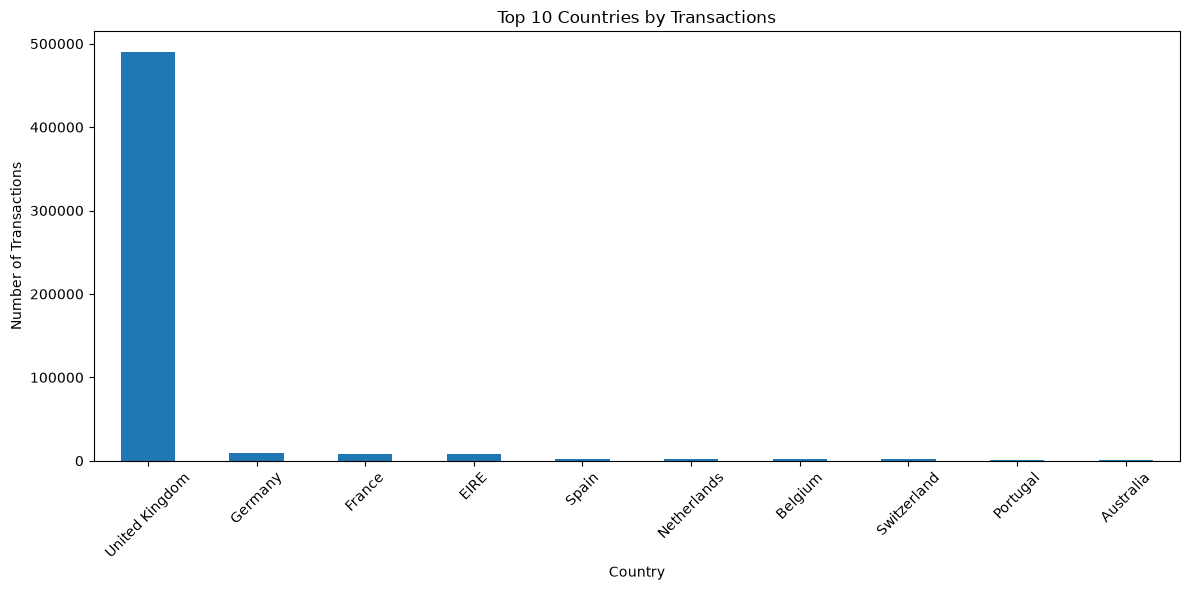

In [8]:
# Top 10 Countries Bar Chart

plt.figure(figsize=(12, 6))

country_counts.plot(kind='bar')

plt.title('Top 10 Countries by Transactions')
plt.xlabel('Country')
plt.ylabel('Number of Transactions')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# Extract month from InvoiceDate

df['Month'] = df['InvoiceDate'].dt.to_period('M')

# Count transactions month-wise
monthly_transactions = df.groupby('Month')['InvoiceNo'].nunique()

print(monthly_transactions)

Month
2010-12    2025
2011-01    1476
2011-02    1393
2011-03    1983
2011-04    1744
2011-05    2162
2011-06    2012
2011-07    1927
2011-08    1737
2011-09    2327
2011-10    2637
2011-11    3462
2011-12    1015
Freq: M, Name: InvoiceNo, dtype: int64


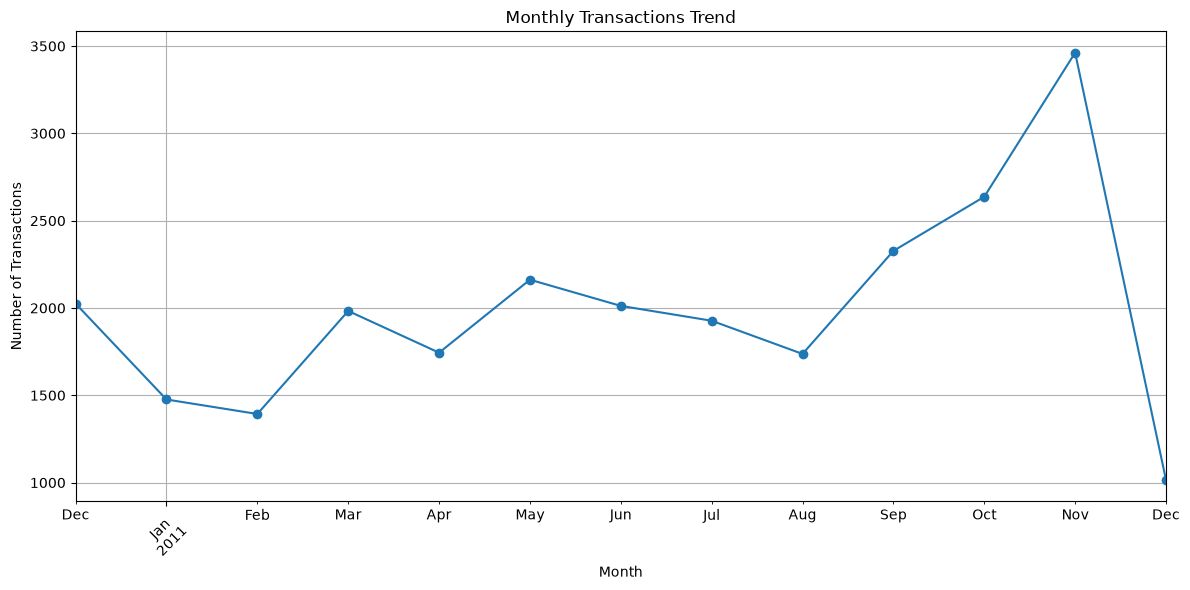

In [10]:
# Monthly Transactions Line Chart

plt.figure(figsize=(12, 6))

monthly_transactions.plot(kind='line', marker='o')

plt.title('Monthly Transactions Trend')
plt.xlabel('Month')
plt.ylabel('Number of Transactions')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [11]:
# Top 10 Products by Quantity Sold

top_products = (
    df.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53751
JUMBO BAG RED RETROSPOT               47260
POPCORN HOLDER                        36322
ASSORTED COLOUR BIRD ORNAMENT         36282
PACK OF 72 RETROSPOT CAKE CASES       36016
WHITE HANGING HEART T-LIGHT HOLDER    35298
RABBIT NIGHT LIGHT                    30631
MINI PAINT SET VINTAGE                26437
PACK OF 12 LONDON TISSUES             26299
PACK OF 60 PINK PAISLEY CAKE CASES    24719
Name: Quantity, dtype: int64


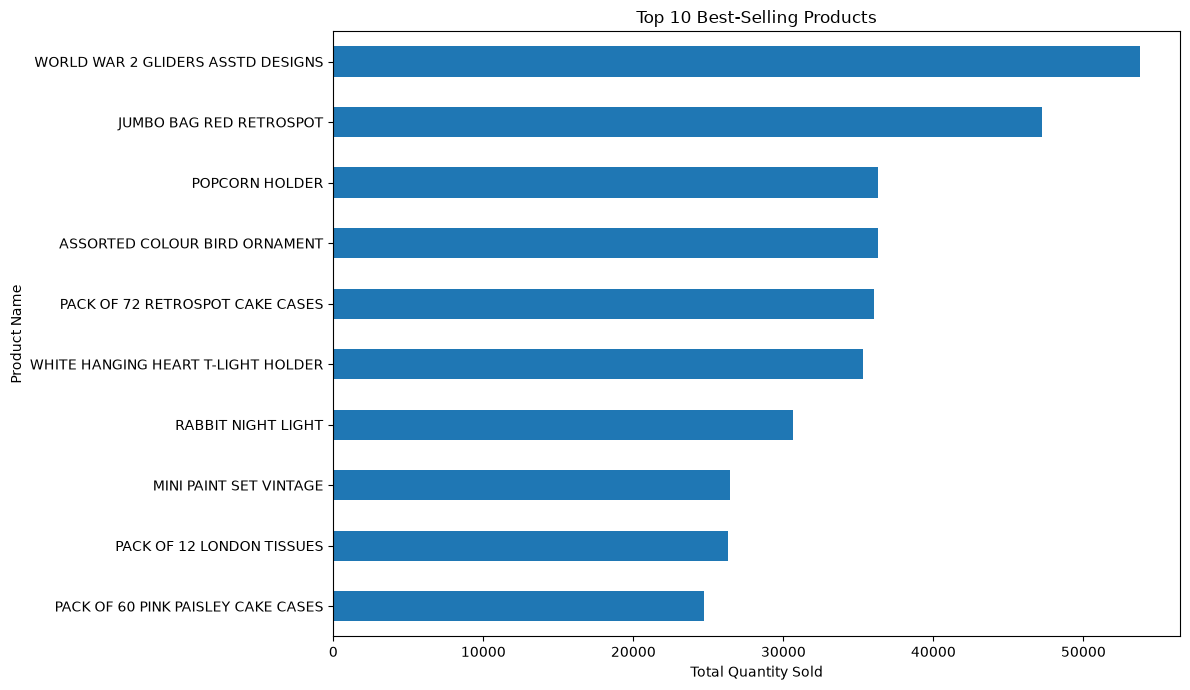

In [12]:
# Top 10 Products Bar Chart

plt.figure(figsize=(12, 7))

top_products.sort_values().plot(kind='barh')

plt.title('Top 10 Best-Selling Products')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product Name')

plt.tight_layout()
plt.show()

In [13]:
# Calculate total sales amount

df['Sales'] = df['Quantity'] * df['UnitPrice']

# Monthly Sales Analysis

monthly_sales = df.groupby(
    df['InvoiceDate'].dt.to_period('M')
)['Sales'].sum()

print(monthly_sales.round(2))

InvoiceDate
2010-12     746723.61
2011-01     558448.56
2011-02     497026.41
2011-03     682013.98
2011-04     492367.84
2011-05     722094.10
2011-06     689977.23
2011-07     680156.99
2011-08     681386.46
2011-09    1017596.68
2011-10    1069368.23
2011-11    1456145.80
2011-12     432701.06
Freq: M, Name: Sales, dtype: float64


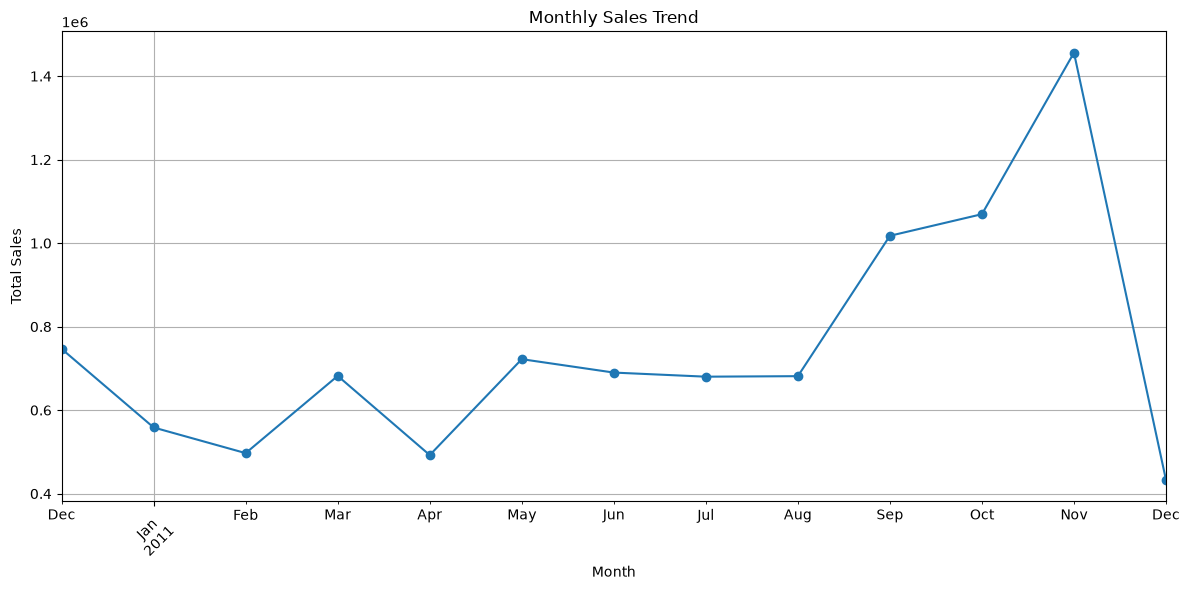

In [14]:
# Monthly Sales Trend

plt.figure(figsize=(12, 6))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:
# Country-wise Sales Analysis

country_sales = (
    df.groupby('Country')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(country_sales.round(2))

Country
United Kingdom    8167128.18
Netherlands        284661.54
EIRE               262993.38
Germany            221509.47
France             197317.11
Australia          137009.77
Switzerland         56363.05
Spain               54756.03
Belgium             40910.96
Sweden              36585.41
Name: Sales, dtype: float64


In [18]:
# Country-wise Sales Analysis

country_sales = (
    df.groupby('Country')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(country_sales.round(2))

Country
United Kingdom    8167128.18
Netherlands        284661.54
EIRE               262993.38
Germany            221509.47
France             197317.11
Australia          137009.77
Switzerland         56363.05
Spain               54756.03
Belgium             40910.96
Sweden              36585.41
Name: Sales, dtype: float64


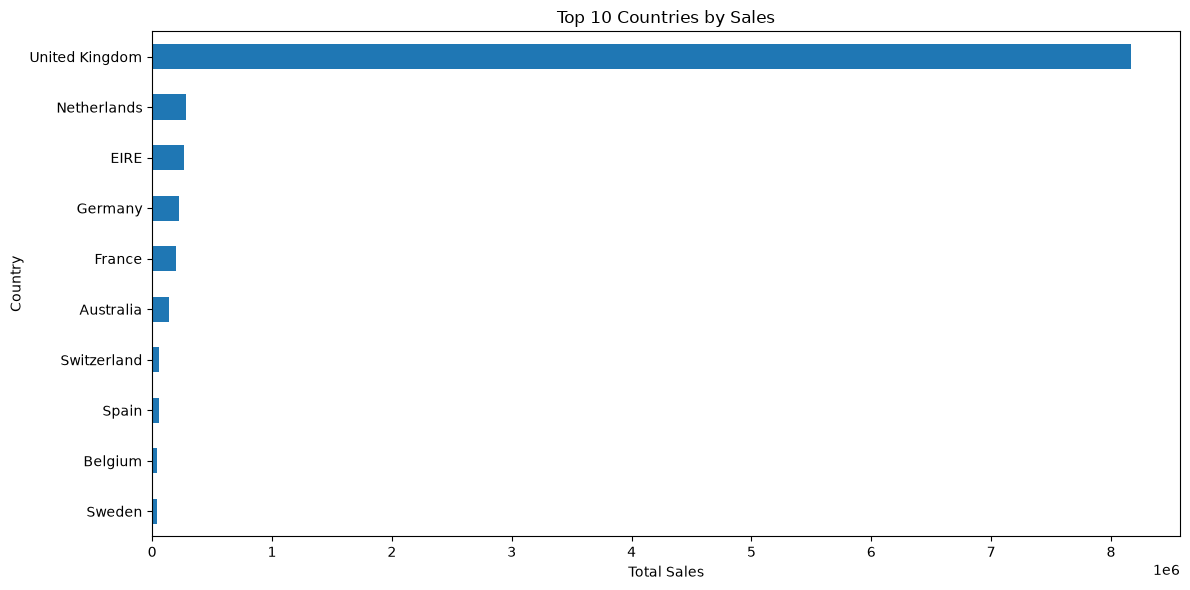

In [19]:
plt.figure(figsize=(12, 6))

country_sales.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

In [20]:
# Negative Quantity Analysis

negative_quantity = (df['Quantity'] < 0).sum()
positive_quantity = (df['Quantity'] > 0).sum()
zero_quantity = (df['Quantity'] == 0).sum()

print("Negative Quantity:", negative_quantity)
print("Positive Quantity:", positive_quantity)
print("Zero Quantity:", zero_quantity)

Negative Quantity: 10587
Positive Quantity: 526054
Zero Quantity: 0


In [21]:
# Unit Price Analysis

negative_price = (df['UnitPrice'] < 0).sum()
zero_price = (df['UnitPrice'] == 0).sum()
positive_price = (df['UnitPrice'] > 0).sum()

print("Negative Unit Price:", negative_price)
print("Zero Unit Price:", zero_price)
print("Positive Unit Price:", positive_price)

Negative Unit Price: 2
Zero Unit Price: 2510
Positive Unit Price: 534129


In [22]:
# Extract Hour from InvoiceDate

df['Hour'] = df['InvoiceDate'].dt.hour

hourly_transactions = df.groupby('Hour')['InvoiceNo'].nunique()

print(hourly_transactions)

Hour
6       22
7       31
8      624
9     1824
10    2961
11    3165
12    3962
13    3369
14    3137
15    3069
16    1952
17    1205
18     333
19     219
20      28
Name: InvoiceNo, dtype: int64


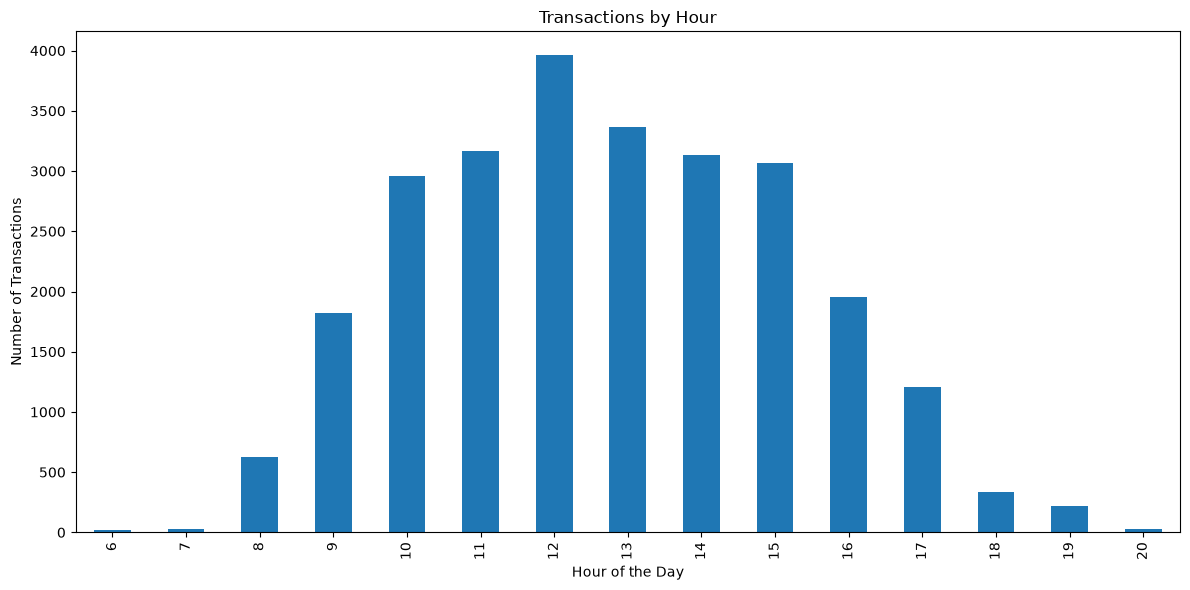

In [23]:
plt.figure(figsize=(12, 6))

hourly_transactions.plot(kind='bar')

plt.title('Transactions by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Number of Transactions')

plt.tight_layout()
plt.show()

In [24]:
# Business KPIs

total_records = len(df)
total_invoices = df['InvoiceNo'].nunique()
total_customers = df['CustomerID'].nunique()
total_products = df['StockCode'].nunique()
total_sales = df['Sales'].sum()

print("Total Records:", total_records)
print("Total Invoices:", total_invoices)
print("Total Customers:", total_customers)
print("Total Products:", total_products)
print("Total Net Sales:", round(total_sales, 2))

Total Records: 536641
Total Invoices: 25900
Total Customers: 4372
Total Products: 4070
Total Net Sales: 9726006.95


Conclusion

This Exploratory Data Analysis project was performed using Python on the cleaned Online Retail dataset.

The analysis included:

Dataset overview and statistical analysis.
Missing value analysis.
Country-wise sales analysis.
Monthly sales trends.
Top-selling product analysis.
Hourly transaction analysis.
Negative quantity and price analysis.
Business KPI calculations.
Data visualization using Matplotlib and Seaborn.

The analysis helped identify important business patterns, sales trends, product performance, and data quality issues.